# 2024 HLT diphoton trigger efficiency, eta-R9 map with NF -- build CSV, JSONs and plots

**Purpose:** turn the tag-and-probe fits of the 2024 run with the normalising-flow (NF) eta-R9 map
into the repo deliverables: a CSV in the 2023 schema, HiggsDNA `TriggerSF_LM` correctionlib JSONs,
efficiency plots and the fit plots, for the normal and the fullPath selection.

**Inputs:**
- `HLT_2024_withPresel_SS/` and `HLT_2024_withPresel_fullPath_SS/` -- fitter output with NF map
  (`egammaEffi.txt` and fit PNGs per category). Byte-identical to
  `etaR9_map_study/data/inputs/new_results/` of the 2024 repo clone.
- `etaR9_map_study/data/fit_yields.csv` -- fit statuses read from the `*Fit.root` files (notebook 03).

**Outputs** (under `HLT-diphoton-efficiency-2024-NF-results/`, `fullPath/` holds the same for fullPath):
- `csvs/hlt_2024_NF_trigger_efficiency_asym_errors.csv`
- `jsons/2024/Lowmass_{seeded,unseeded}_leg_efficinecy.json`
- `efficiency_plots/efficiency-data-passing_{seeded,unseeded}_2024_withNF.{png,pdf}`
- `fit_plots/{seeded,unseeded}/<category>/sig_bwDscb_bkg_{RooCMSShape,Exponential}/bin*.png`

**Gates:** every efficiency in `egammaEffi.txt` must be a round-off of the value printed on its fit PNG
(OCR); errors must equal max(PNG error, 0.001); OCR fit status must equal the stored fit status;
every JSON cell must return the CSV value through correctionlib. Each gate is run once on a
deliberately broken input and must fail there.

## 1. Imports

In [1]:
import csv
import hashlib
import json
import re
import shutil
import subprocess
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import correctionlib
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

%matplotlib inline

## 2. Config

In [2]:
BASE = Path("/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw")
OLD_REPO = BASE / "HLT-diphoton-efficiency-2024-results"
NEW_REPO = BASE / "HLT-diphoton-efficiency-2024-NF-results"

SETS = ["normal", "fullPath"]
FITTER_DIR = {
    "normal": BASE / "HLT_2024_withPresel_SS",
    "fullPath": BASE / "HLT_2024_withPresel_fullPath_SS",
}
OLD_REPO_FIT_PLOTS = {
    "normal": OLD_REPO / "fit_plots" / "etaR9rw_withPresel_with_NF",
    "fullPath": OLD_REPO / "fit_plots" / "etaR9rw_withPresel_with_NF_fullPath",
}
SET_ROOT = {"normal": NEW_REPO, "fullPath": NEW_REPO / "fullPath"}
CSV_NAME = {
    "normal": "hlt_2024_NF_trigger_efficiency_asym_errors.csv",
    "fullPath": "hlt_2024_NF_trigger_efficiency_fullPath_asym_errors.csv",
}
FIT_YIELDS = OLD_REPO / "etaR9_map_study" / "data" / "fit_yields.csv"
OCR_CSV = BASE / "diagnostics" / "2026-10-21_nf_png_ocr.csv"
TESSERACT = Path(sys.prefix) / "bin" / "tesseract"

LEGS = ["seed", "unseed"]
LEG_DIR = {"seed": "seeded", "unseed": "unseeded"}
CATS = ["EB_R9_0p50to0p55", "EB_R9_0p55to0p85", "EB_R9gt0p85", "EE_R9_0p90to0p93", "EE_R9gt0p93"]
# fit model: egammaEffi.txt column group, fitter plot dir, repo plot dir
MODELS = {
    "cms": ("bwDscbCms", "bwDscbCmsFit", "sig_bwDscb_bkg_RooCMSShape"),
    "exp": ("bwDscbExp", "bwDscbExpFit", "sig_bwDscb_bkg_Exponential"),
}
# egammaEffi.txt column groups, in file order; each is (eff, err_lo, err_hi)
TXT_VARIANTS = [
    "nomFit", "nomExpFit", "altSigFit", "altBkgFit",
    "altSigAddGaus", "altBkgAddGaus", "bwDscbCms", "bwDscbExp",
]
ERR_FLOOR = 0.001        # egm_tnp rootUtils.py computeEffi floor on the text-file error
TOL = 0.000055           # half a unit of the PNG's 4th decimal, plus the txt file's own 5th-decimal rounding

assert TESSERACT.exists(), TESSERACT
for s in SETS:
    assert FITTER_DIR[s].is_dir(), FITTER_DIR[s]
    assert OLD_REPO_FIT_PLOTS[s].is_dir(), OLD_REPO_FIT_PLOTS[s]
print("NEW_REPO :", NEW_REPO)
print("tesseract:", TESSERACT)

NEW_REPO : /home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results
tesseract: /home/santanu/micromamba/envs/claude_env/bin/tesseract


## 3. Parse `egammaEffi.txt`

Same parser as the 2024 repo notebook (`2026-07-14_build_eff_csv_and_plots.ipynb`, cell 6), keeping
only `bwDscbCms` and `bwDscbExp`.

In [3]:
def read_egamma_effi(path):
    out = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("###"):
            continue
        parts = line.split()
        assert len(parts) == 4 + 3 * len(TXT_VARIANTS), (path, line)
        et_lo, et_hi = float(parts[2]), float(parts[3])
        for model, (txt_name, _, _) in MODELS.items():
            i = TXT_VARIANTS.index(txt_name)
            out.append({
                "et_lo": et_lo, "et_hi": et_hi, "model": model,
                "eff": float(parts[4 + 3 * i]),
                "err_lo": float(parts[5 + 3 * i]),
                "err_hi": float(parts[6 + 3 * i]),
            })
    return out


txt_rows = []
for s in SETS:
    for leg in LEGS:
        for cat in CATS:
            txt = FITTER_DIR[s] / f"passingHLT_{leg}_{cat}_2024" / "egammaEffi.txt"
            for r in read_egamma_effi(txt):
                txt_rows.append({"set": s, "leg": leg, "cat": cat, **r})

txt_df = pd.DataFrame(txt_rows)
print("txt rows:", len(txt_df))
print(txt_df.groupby(["set", "leg", "model"]).size())
assert len(txt_df) == 2 * (5 * 9 + 5 * 12) * 2   # 2 sets x (seed 9 bins + unseed 12 bins) x 5 cats x 2 models
assert (txt_df["eff"] >= 0).all(), "a bwDscb variant was not fitted (-1 sentinel)"

txt rows: 420
set       leg     model
fullPath  seed    cms      45
                  exp      45
          unseed  cms      60
                  exp      60
normal    seed    cms      45
                  exp      45
          unseed  cms      60
                  exp      60
dtype: int64


## 4. Stage the fit plots into the new repo

Copied from the fitter directories, then checked byte-for-byte against the copies already in the
2024 repo clone, so the published PNGs are the ones the explorer shows.

In [4]:
BIN_RE = re.compile(r"bin(\d+)_ph_sc_abseta_([0-9p]+)To([0-9p]+)_ph_sc_et_([0-9p]+)To([0-9p]+)\.png$")


def md5(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


png_rows = []
for s in SETS:
    for leg in LEGS:
        for cat in CATS:
            for model, (_, fitter_sub, repo_sub) in MODELS.items():
                src_dir = (FITTER_DIR[s] / f"passingHLT_{leg}_{cat}_2024" / "plots"
                           / f"data_2024_withPresel_{leg}_{cat}" / fitter_sub)
                dst_dir = SET_ROOT[s] / "fit_plots" / LEG_DIR[leg] / cat / repo_sub
                ref_dir = OLD_REPO_FIT_PLOTS[s] / LEG_DIR[leg] / cat / repo_sub
                dst_dir.mkdir(parents=True, exist_ok=True)
                for src in sorted(src_dir.glob("bin*.png")):
                    m = BIN_RE.search(src.name)
                    assert m, src
                    dst = dst_dir / src.name
                    shutil.copy2(src, dst)
                    assert md5(dst) == md5(ref_dir / src.name), f"differs from 2024 repo copy: {src.name}"
                    png_rows.append({
                        "set": s, "leg": leg, "cat": cat, "model": model,
                        "et_lo": float(m.group(4).replace("p", ".")),
                        "et_hi": float(m.group(5).replace("p", ".")),
                        "png": str(dst),
                    })

png_df = pd.DataFrame(png_rows)
print("PNGs staged:", len(png_df))
assert len(png_df) == len(txt_df) == 420   # 2 sets x 105 pt bins x 2 models

PNGs staged: 420


## 5. OCR the header of every fit PNG

Same crop as the 2023 OCR script (`2026-06-25_ocr_eff_from_pngs.py:28-40`): top-left third, 80 px
high, which holds `* fit status pass: P, fail : F` and `* eff = E +H -L`.

In [5]:
EFF_RE = re.compile(r"eff\s*=\s*([0-9.]+)\s*\+\s*([0-9.]+)\s*-\s*([0-9.]+)")
STATUS_RE = re.compile(r"pass:\s*(-?\d+)\s*,\s*fail\s*:\s*(-?\d+)")


def ocr_header(png_path):
    im = Image.open(png_path)
    crop = im.crop((0, 0, im.size[0] // 3, 80))
    tmp = OCR_CSV.parent / ("crop_" + hashlib.md5(str(png_path).encode()).hexdigest() + ".png")
    crop.save(tmp)
    text = subprocess.run([str(TESSERACT), str(tmp), "-"], capture_output=True, text=True).stdout
    tmp.unlink()
    e = EFF_RE.search(text)
    st = STATUS_RE.search(text)
    return {
        "png": str(png_path),
        "png_eff": float(e.group(1)) if e else None,
        "png_err_hi": float(e.group(2)) if e else None,
        "png_err_lo": float(e.group(3)) if e else None,
        "png_status_pass": int(st.group(1)) if st else None,
        "png_status_fail": int(st.group(2)) if st else None,
        "ocr_raw": text.strip(),
    }


OCR_CSV.parent.mkdir(parents=True, exist_ok=True)
with ThreadPoolExecutor(max_workers=8) as pool:
    ocr = pd.DataFrame(list(pool.map(ocr_header, png_df["png"])))
ocr.to_csv(OCR_CSV, index=False)

unparsed = ocr[ocr[["png_eff", "png_status_pass"]].isna().any(axis=1)]
print("OCR'd:", len(ocr), " unparsed:", len(unparsed))
print(unparsed[["png", "ocr_raw"]].to_string())
assert len(unparsed) == 0, "OCR did not read every header -- inspect these PNGs"
print("OCR table:", OCR_CSV)

OCR'd: 420  unparsed: 0
Empty DataFrame
Columns: [png, ocr_raw]
Index: []
OCR table: /home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/diagnostics/2026-10-21_nf_png_ocr.csv


## 6. Gate: `egammaEffi.txt` vs fit PNG

- coverage: one PNG per txt row and one txt row per PNG
- efficiency: |txt - PNG| <= `TOL`, i.e. the PNG value is the txt value rounded
- errors: txt error = max(PNG error, 0.001), within `TOL` (the fitter floors only the text file)

In [6]:
KEY = ["set", "leg", "cat", "model", "et_lo", "et_hi"]


def compare_txt_png(txt, png, ocr_table):
    merged = txt.merge(png.merge(ocr_table, on="png"), on=KEY, how="outer", indicator=True)
    bad = {"coverage": merged[merged["_merge"] != "both"]}
    both = merged[merged["_merge"] == "both"]
    bad["eff"] = both[(both["eff"] - both["png_eff"]).abs() > TOL]
    for side in ("hi", "lo"):
        floored = both[f"png_err_{side}"].clip(lower=ERR_FLOOR)
        bad[f"err_{side}"] = both[(both[f"err_{side}"] - floored).abs() > TOL]
    return merged, bad


merged, bad = compare_txt_png(txt_df, png_df, ocr)
for name, rows in bad.items():
    print(f"{name:9s} failures: {len(rows)}")
print("rows compared:", (merged["_merge"] == "both").sum())
print("largest |txt eff - PNG eff|:", (merged["eff"] - merged["png_eff"]).abs().max())
for name, rows in bad.items():
    assert len(rows) == 0, f"gate failed on {name}:\n{rows[KEY].to_string()}"

# Known-bad input: shift one efficiency by 1e-4; the gate must catch exactly that row.
broken = txt_df.copy()
broken.loc[0, "eff"] += 0.0001
_, bad_test = compare_txt_png(broken, png_df, ocr)
assert len(bad_test["eff"]) == 1, "eff gate did not catch a 1e-4 shift"
broken = txt_df.copy()
broken.loc[0, "err_hi"] += 0.0001
_, bad_test = compare_txt_png(broken, png_df, ocr)
assert len(bad_test["err_hi"]) == 1, "error gate did not catch a 1e-4 shift"
_, bad_test = compare_txt_png(txt_df.iloc[1:], png_df, ocr)
assert len(bad_test["coverage"]) == 1, "coverage gate did not catch a missing row"
print("gate self-test: catches a shifted eff, a shifted error and a missing row")

coverage  failures: 0
eff       failures: 0
err_hi    failures: 0
err_lo    failures: 0
rows compared: 420
largest |txt eff - PNG eff|: 5.0000000000105516e-05
gate self-test: catches a shifted eff, a shifted error and a missing row


## 7. Gate: OCR fit status vs status stored in the fit `.root` files

`fit_yields.csv` (`src == "wNF"`) holds `statusP`/`statusF` read from the `*Fit.root` files.

In [7]:
fy = pd.read_csv(FIT_YIELDS)
fy = fy[fy["src"] == "wNF"].copy()
fy["model"] = fy["model"].map({"bwDscbCms": "cms", "bwDscbExp": "exp"})
fy = fy[["set", "leg", "cat", "model", "et_lo", "et_hi", "statusP", "statusF", "eff_fit"]]
fy[["et_lo", "et_hi"]] = fy[["et_lo", "et_hi"]].astype(float)


def compare_status(merged_table, stored):
    m = merged_table.merge(stored, on=KEY, how="left", indicator="_fy")
    missing = m[m["_fy"] != "both"]
    differ = m[(m["png_status_pass"] != m["statusP"]) | (m["png_status_fail"] != m["statusF"])]
    return missing, differ


missing, differ = compare_status(merged[merged["_merge"] == "both"].drop(columns="_merge"), fy)
print("stored-status rows matched:", len(fy), " missing:", len(missing), " differ:", len(differ))
assert len(missing) == 0 and len(differ) == 0, differ[KEY + ["png_status_pass", "statusP", "png_status_fail", "statusF"]]

fy_broken = fy.copy()
fy_broken.loc[fy_broken.index[0], "statusP"] += 1
_, differ_test = compare_status(merged[merged["_merge"] == "both"].drop(columns="_merge"), fy_broken)
assert len(differ_test) == 1, "status gate did not catch a changed status"
print("gate self-test: catches a changed status")

print("\nfit status counts (pass, fail) per model:")
print(merged.groupby(["model", "png_status_pass", "png_status_fail"]).size())

stored-status rows matched: 420  missing: 0  differ: 0
gate self-test: catches a changed status

fit status counts (pass, fail) per model:
model  png_status_pass  png_status_fail
cms    0                0                  76
                        4                  37
       4                0                  61
                        4                  36
exp    0                0                  92
                        4                  34
       4                0                  49
                        4                  35
dtype: int64


## 8. Build the CSVs (2023 schema plus the unfloored PNG errors)

As the 2023 builder (`2026-06-25_build_repo_artifacts.py:74-120`): `err_hi` capped at 1 - eff,
`bkg_syst = |eff_cms - eff_exp|`, `total_unc = err (+) bkg_syst`, `total_unc_hi` capped at
1 - eff_cms; errors rounded to 4 decimals, totals to 6. `err_*_png` are the PNG errors.

`eff_cms`/`eff_exp` are the PNG values, not the txt value rounded again: the txt file keeps 5 decimals,
so a value ending in 5 (e.g. 0.97275) rounds to the other side of the 4-decimal value the fitter
printed from full precision. Section 6 already bounds |txt - PNG| by `TOL`; the check below requires
every row where the two roundings differ to be such a half-way case. Totals use the txt values.

In [8]:
def cap_err_hi(eff, err_hi):
    return min(err_hi, max(0.0, 1.0 - eff))


both = merged[merged["_merge"] == "both"]
csv_rows = {s: [] for s in SETS}
for (s, leg, cat, et_lo, et_hi), g in both.groupby(["set", "leg", "cat", "et_lo", "et_hi"], sort=False):
    c = g[g["model"] == "cms"].iloc[0]
    e = g[g["model"] == "exp"].iloc[0]
    ehi_c = cap_err_hi(c["eff"], c["err_hi"])
    ehi_e = cap_err_hi(e["eff"], e["err_hi"])
    bkg_syst = abs(c["eff"] - e["eff"])
    total_hi = min((ehi_c ** 2 + bkg_syst ** 2) ** 0.5, max(0.0, 1.0 - c["eff"]))
    total_lo = (c["err_lo"] ** 2 + bkg_syst ** 2) ** 0.5
    csv_rows[s].append({
        "era": "2024", "trigger": leg, "eta_r9_bin": cat, "pt_lo": et_lo, "pt_hi": et_hi,
        "eff_cms": c["png_eff"], "err_hi_cms": round(ehi_c, 4), "err_lo_cms": round(c["err_lo"], 4),
        "err_hi_cms_png": c["png_err_hi"], "err_lo_cms_png": c["png_err_lo"],
        "status_pass_cms": int(c["png_status_pass"]), "status_fail_cms": int(c["png_status_fail"]),
        "eff_exp": e["png_eff"], "err_hi_exp": round(ehi_e, 4), "err_lo_exp": round(e["err_lo"], 4),
        "err_hi_exp_png": e["png_err_hi"], "err_lo_exp_png": e["png_err_lo"],
        "status_pass_exp": int(e["png_status_pass"]), "status_fail_exp": int(e["png_status_fail"]),
        "bkg_syst": round(bkg_syst, 4),
        "total_unc_hi": round(total_hi, 6), "total_unc_lo": round(total_lo, 6),
    })

csv_df = {}
for s in SETS:
    rows = sorted(csv_rows[s], key=lambda r: (r["trigger"], CATS.index(r["eta_r9_bin"]), r["pt_lo"]))
    out = SET_ROOT[s] / "csvs" / CSV_NAME[s]
    out.parent.mkdir(parents=True, exist_ok=True)
    with open(out, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)
    csv_df[s] = pd.read_csv(out)
    print(f"{s:8s}: {len(rows)} rows -> {out}")
    assert len(rows) == 105

# Where round(txt, 4) differs from the PNG, the txt value must be a half-way case (5th decimal = 5).
both = both.assign(txt_5th_digit=(both["eff"] * 1e5).round().astype(int) % 10,
                   txt_rounded=both["eff"].round(4))
differs = both[(both["txt_rounded"] - both["png_eff"]).abs() > 1e-9]
print(f"rows where round(txt, 4) != PNG: {len(differs)} of {len(both)}")
print(differs[KEY + ["eff", "txt_rounded", "png_eff"]].to_string())
assert (differs["txt_5th_digit"] == 5).all(), "a txt/PNG difference that is not a half-way rounding case"

# The CSV holds the PNG values, row for row.
for s in SETS:
    chk = csv_df[s].merge(
        both[(both["set"] == s)].pivot_table(index=["leg", "cat", "et_lo", "et_hi"], columns="model",
                                             values="png_eff").reset_index(),
        left_on=["trigger", "eta_r9_bin", "pt_lo", "pt_hi"], right_on=["leg", "cat", "et_lo", "et_hi"])
    n_c = (chk["eff_cms"] - chk["cms"]).abs().gt(1e-9).sum()
    n_e = (chk["eff_exp"] - chk["exp"]).abs().gt(1e-9).sum()
    print(f"{s:8s}: CSV eff != PNG eff  cms: {n_c}  exp: {n_e}  (of {len(chk)})")
    assert len(chk) == 105 and n_c == 0 and n_e == 0
csv_df["normal"].head()

normal  : 105 rows -> /home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/csvs/hlt_2024_NF_trigger_efficiency_asym_errors.csv
fullPath: 105 rows -> /home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/fullPath/csvs/hlt_2024_NF_trigger_efficiency_fullPath_asym_errors.csv
rows where round(txt, 4) != PNG: 16 of 420
          set     leg               cat model  et_lo     et_hi      eff  txt_rounded  png_eff
2    fullPath    seed  EB_R9_0p50to0p55   cms   37.0      40.0  0.95005       0.9500   0.9501
10   fullPath    seed  EB_R9_0p50to0p55   exp   35.0      37.0  0.94045       0.9404   0.9405
41   fullPath    seed       EB_R9gt0p85   cms   50.0      60.0  0.96735       0.9674   0.9673
77   fullPath    seed       EE_R9gt0p93   cms   50.0      60.0  0.97825       0.9782   0.9783
89   fullPath    seed       EE_R9gt0p93   exp   90.0  999999.0  0.98995       0.9900   0.9899
134  fullPath  unseed

,era,trigger,eta_r9_bin,pt_lo,pt_hi,eff_cms,err_hi_cms,err_lo_cms,err_hi_cms_png,err_lo_cms_png,...,eff_exp,err_hi_exp,err_lo_exp,err_hi_exp_png,err_lo_exp_png,status_pass_exp,status_fail_exp,bkg_syst,total_unc_hi,total_unc_lo
0,2024,seed,EB_R9_0p50to0p55,0.0,35.0,0.8113,0.0023,0.0023,0.0023,0.0023,...,0.7946,0.0012,0.0012,0.0012,0.0012,0,0,0.0167,0.016903,0.016903
1,2024,seed,EB_R9_0p50to0p55,35.0,37.0,0.8944,0.0013,0.0014,0.0013,0.0014,...,0.8869,0.0012,0.0012,0.0012,0.0012,0,0,0.0075,0.007582,0.007608
2,2024,seed,EB_R9_0p50to0p55,37.0,40.0,0.9034,0.0010,0.0010,0.0009,0.0009,...,0.9033,0.0010,0.0010,0.0008,0.0008,0,0,0.0001,0.001006,0.001006
3,2024,seed,EB_R9_0p50to0p55,40.0,45.0,0.9138,0.0010,0.0010,0.0007,0.0007,...,0.9132,0.0010,0.0010,0.0007,0.0007,0,4,0.0006,0.001151,0.001151
4,2024,seed,EB_R9_0p50to0p55,45.0,50.0,0.9191,0.0011,0.0013,0.0011,0.0013,...,0.9178,0.0010,0.0010,0.0004,0.0004,0,0,0.0013,0.001700,0.001789


## 9. Build the `TriggerSF_LM` JSONs

Format of HiggsDNA `JSONs/TriggerSF_LM/2022postEE/Lowmass_{seeded,unseeded}_leg_efficinecy.json`:
`systematic` category with `up`/`down`, nominal in `default`, multibinning (SCEta, r9, pt), flow clamp.
Read by `TriggerSF_LM` in `event_weight_systematics.py` as `evaluate("nominal", |ScEta|, r9, pt)`.

- SCEta `[0, 1.4442, 1.566, 2.5, 999]`; r9 `[0, 0.50, 0.55, 0.85, 0.90, 0.93, 999]`; pt = measured bins.
- EB/EE cells map one-to-one onto the measured categories (table below); every other cell is 1.0.
- nominal = `eff_cms`; up = min(1, eff + `total_unc_hi`); down = max(0, eff - `total_unc_lo`).

In [9]:
SCETA_EDGES = [0.0, 1.4442, 1.566, 2.5, 999.0]
R9_EDGES = [0.0, 0.50, 0.55, 0.85, 0.90, 0.93, 999.0]
ONE = None
CELL_SOURCE = [
    # r9: 0-0.50   0.50-0.55            0.55-0.85            0.85-0.90      0.90-0.93           >0.93
    [ONE, "EB_R9_0p50to0p55", "EB_R9_0p55to0p85", "EB_R9gt0p85", "EB_R9gt0p85", "EB_R9gt0p85"],  # |eta| < 1.4442
    [ONE, ONE, ONE, ONE, ONE, ONE],                                                                # gap
    [ONE, ONE, ONE, ONE, "EE_R9_0p90to0p93", "EE_R9gt0p93"],                                     # 1.566-2.5
    [ONE, ONE, ONE, ONE, ONE, ONE],                                                                # > 2.5
]
JSON_NAME = {"seed": "Lowmass_seeded_leg_efficinecy.json", "unseed": "Lowmass_unseeded_leg_efficinecy.json"}
CORR_DESC = {"seed": "Lead Photon Trigger Scale Factor", "unseed": "Sublead Photon Trigger Scale Factor"}


def build_tables(table, leg):
    rows = table[table["trigger"] == leg]
    pt_lo = sorted(rows["pt_lo"].unique())
    pt_edges = pt_lo + [rows["pt_hi"].max()]
    nom, up, down = [], [], []
    for eta_row in CELL_SOURCE:
        for cat in eta_row:
            if cat is ONE:
                n_pt = len(pt_edges) - 1
                nom += [1.0] * n_pt
                up += [1.0] * n_pt
                down += [1.0] * n_pt
                continue
            bins = rows[rows["eta_r9_bin"] == cat].sort_values("pt_lo")
            assert list(bins["pt_lo"]) == pt_lo, (leg, cat)
            for _, b in bins.iterrows():
                eff = min(1.0, max(0.0, b["eff_cms"]))
                nom.append(round(eff, 6))
                up.append(round(min(1.0, eff + b["total_unc_hi"]), 6))
                down.append(round(max(0.0, eff - b["total_unc_lo"]), 6))
    return pt_edges, nom, up, down


def multibinning(pt_edges, content):
    return {"nodetype": "multibinning", "inputs": ["SCEta", "r9", "pt"],
            "edges": [SCETA_EDGES, R9_EDGES, pt_edges], "content": content, "flow": "clamp"}


def make_payload(table, leg):
    pt_edges, nom, up, down = build_tables(table, leg)
    return {
        "schema_version": 2,
        "description": "Trigger SF",
        "corrections": [{
            "name": "TriggerSF",
            "description": CORR_DESC[leg],
            "version": 1,
            "inputs": [
                {"name": "systematic", "type": "string", "description": "Systematic variation"},
                {"name": "SCEta", "type": "real", "description": "Photon Super Cluster eta absolute value"},
                {"name": "r9", "type": "real",
                 "description": ("Photon full 5x5 R9, ratio E3x3/ERAW, where E3x3 is the energy sum of the 3 by 3 "
                                 "crystals surrounding the supercluster seed crystal and ERAW is the raw energy "
                                 "sum of the supercluster")},
                {"name": "pt", "type": "real", "description": "Photon pt"},
            ],
            "output": {"name": "Wcorr", "type": "real",
                       "description": "Multiplicative correction to event weight (per-photon)"},
            "generic_formulas": None,
            "data": {
                "nodetype": "category", "input": "systematic",
                "content": [
                    {"key": "up", "value": multibinning(pt_edges, up)},
                    {"key": "down", "value": multibinning(pt_edges, down)},
                ],
                "default": multibinning(pt_edges, nom),
            },
        }],
        "compound_corrections": None,
    }


json_paths = {}
for s in SETS:
    for leg in LEGS:
        payload = make_payload(csv_df[s], leg)
        out = SET_ROOT[s] / "jsons" / "2024" / JSON_NAME[leg]
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_text(json.dumps(payload, indent=2))
        json_paths[(s, leg)] = out
        print(out)

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/jsons/2024/Lowmass_seeded_leg_efficinecy.json
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/jsons/2024/Lowmass_unseeded_leg_efficinecy.json
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/fullPath/jsons/2024/Lowmass_seeded_leg_efficinecy.json
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/fullPath/jsons/2024/Lowmass_unseeded_leg_efficinecy.json


## 10. Gate: evaluate every JSON cell with correctionlib

For each CSV row, evaluate at the bin centre (|eta| centre of EB/EE, every r9 cell the category feeds,
pt centre; 200 GeV for the last bin) and require nominal/up/down to equal the CSV-derived value.
Every 1.0 cell is probed too. Then the same gate runs on a JSON with one value changed.

In [10]:
ETA_POINT = {"EB": 0.7, "EE": 2.0}
R9_POINTS = {
    "EB_R9_0p50to0p55": [0.52], "EB_R9_0p55to0p85": [0.7], "EB_R9gt0p85": [0.87, 0.91, 0.97],
    "EE_R9_0p90to0p93": [0.915], "EE_R9gt0p93": [0.97],
}
ONE_POINTS = [  # (|eta|, r9): out-of-selection cells that must return 1.0
    (0.7, 0.3), (2.0, 0.3), (2.0, 0.52), (2.0, 0.7), (2.0, 0.87),
    (1.5, 0.7), (1.5, 0.95), (2.7, 0.7), (2.7, 0.95),
]


def check_json(evaluator, table, leg):
    failures = []
    rows = table[table["trigger"] == leg]
    for _, b in rows.iterrows():
        pt = 200.0 if b["pt_hi"] > 1000 else 0.5 * (b["pt_lo"] + b["pt_hi"])
        eff = min(1.0, max(0.0, b["eff_cms"]))
        want = {"nominal": eff, "up": min(1.0, eff + b["total_unc_hi"]), "down": max(0.0, eff - b["total_unc_lo"])}
        for r9 in R9_POINTS[b["eta_r9_bin"]]:
            for syst, value in want.items():
                got = evaluator.evaluate(syst, ETA_POINT[b["eta_r9_bin"][:2]], r9, pt)
                if abs(got - value) > 1e-6:
                    failures.append((b["eta_r9_bin"], b["pt_lo"], r9, syst, got, value))
        for eta, r9 in ONE_POINTS:
            for syst in ("nominal", "up", "down"):
                got = evaluator.evaluate(syst, eta, r9, pt)
                if got != 1.0:
                    failures.append(("ONE", b["pt_lo"], (eta, r9), syst, got, 1.0))
    return failures


for (s, leg), path in json_paths.items():
    ev = correctionlib.CorrectionSet.from_file(str(path))["TriggerSF"]
    fails = check_json(ev, csv_df[s], leg)
    print(f"{s:8s} {leg:6s}: {len(fails)} failures")
    assert not fails, fails[:10]

# Known-bad input: change one nominal value in the EB_R9_0p55to0p85 block.
payload = json.loads(json_paths[("normal", "seed")].read_text())
n_pt = len(payload["corrections"][0]["data"]["default"]["edges"][2]) - 1
payload["corrections"][0]["data"]["default"]["content"][2 * n_pt + 3] += 0.01
ev_bad = correctionlib.CorrectionSet.from_string(json.dumps(payload))["TriggerSF"]
assert check_json(ev_bad, csv_df["normal"], "seed"), "JSON gate did not catch a changed value"
print("gate self-test: catches a changed JSON value")

normal   seed  : 0 failures
normal   unseed: 0 failures
fullPath seed  : 0 failures
fullPath unseed: 0 failures
gate self-test: catches a changed JSON value


## 11. Efficiency plots

Plotting code of the 2024 repo notebook (cell 12): nominal `bwDscbCms` fit, fit errors, catch-all first
pt bin dropped, R9 categories overlaid.

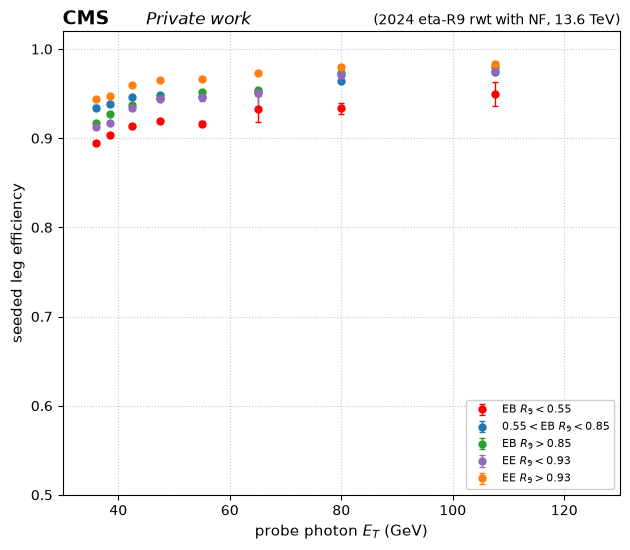

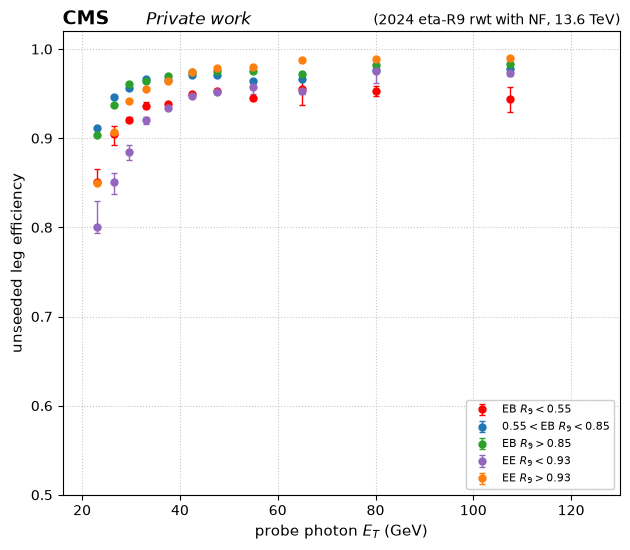

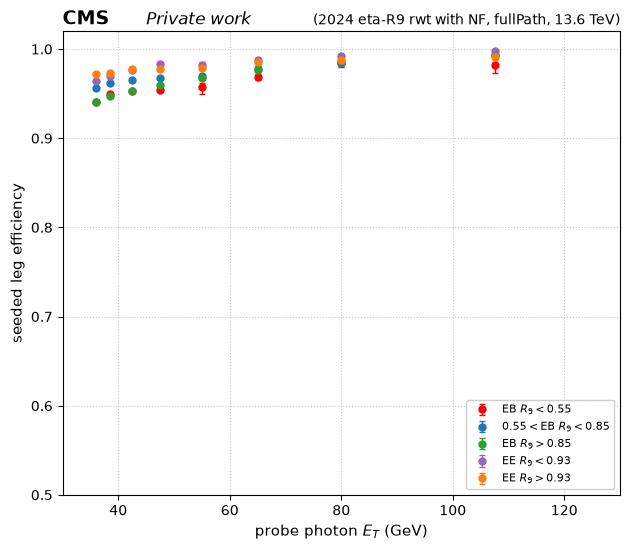

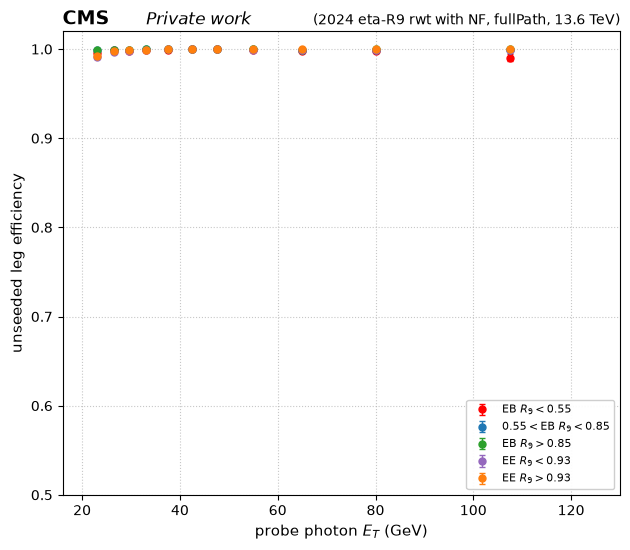

In [11]:
PT_CAP = 120.0
MIN_PT_BY_LEG = {"seed": 35.0, "unseed": 21.0}
LEG_LABEL = {"seed": "seeded", "unseed": "unseeded"}
SET_DISPLAY = {"normal": "eta-R9 rwt with NF", "fullPath": "eta-R9 rwt with NF, fullPath"}
SET_SUFFIX = {"normal": "withNF", "fullPath": "withNF_fullPath"}
R9_CATS = [
    ("EB_R9_0p50to0p55", "EB $R_9 < 0.55$", "red"),
    ("EB_R9_0p55to0p85", "$0.55 < $EB $R_9 < 0.85$", "tab:blue"),
    ("EB_R9gt0p85", "EB $R_9 > 0.85$", "tab:green"),
    ("EE_R9_0p90to0p93", "EE $R_9 < 0.93$", "tab:purple"),
    ("EE_R9gt0p93", "EE $R_9 > 0.93$", "tab:orange"),
]


def xmid(plo, phi):
    return 0.5 * (plo + min(phi, PT_CAP + 5))


def make_plot(s, leg):
    table = csv_df[s]
    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    min_pt = MIN_PT_BY_LEG[leg]
    for cat, label, color in R9_CATS:
        sel = table[(table["trigger"] == leg) & (table["eta_r9_bin"] == cat)
                    & (table["pt_lo"] >= min_pt)].sort_values("pt_lo")
        xs = [xmid(plo, phi) for plo, phi in zip(sel["pt_lo"], sel["pt_hi"])]
        ax.errorbar(xs, sel["eff_cms"], yerr=[sel["err_lo_cms"], sel["err_hi_cms"]],
                    fmt="o", color=color, ms=5, lw=1.0, capsize=2, label=label)
    ax.set_xlim(max(15, min_pt - 5), 130)
    ax.set_ylim(0.5, 1.02)
    ax.grid(True, ls=":", alpha=0.7)
    ax.set_xlabel("probe photon $E_T$ (GeV)", fontsize=11)
    ax.set_ylabel(f"{LEG_LABEL[leg]} leg efficiency", fontsize=11)
    ax.legend(loc="lower right", fontsize=8, framealpha=0.95)
    ax.text(0.0, 1.015, "CMS", transform=ax.transAxes, fontsize=14, fontweight="bold")
    ax.text(0.15, 1.015, "Private work", transform=ax.transAxes, fontsize=12, fontstyle="italic")
    ax.text(1.0, 1.015, f"(2024 {SET_DISPLAY[s]}, 13.6 TeV)", transform=ax.transAxes, fontsize=10, ha="right")
    fig.tight_layout()
    out_dir = SET_ROOT[s] / "efficiency_plots"
    out_dir.mkdir(parents=True, exist_ok=True)
    stem = out_dir / f"efficiency-data-passing_{LEG_LABEL[leg]}_2024_{SET_SUFFIX[s]}"
    fig.savefig(f"{stem}.pdf")
    fig.savefig(f"{stem}.png", dpi=150)
    plt.show()
    plt.close(fig)
    return stem


plot_stems = [make_plot(s, leg) for s in SETS for leg in LEGS]

## 12. Files written

In [12]:
written = sorted(p for p in NEW_REPO.rglob("*") if p.is_file() and "fit_plots" not in p.parts)
for p in written:
    print(p)
n_fit = sum(1 for _ in NEW_REPO.rglob("fit_plots/**/*.png"))
print(f"\n+ {n_fit} fit PNGs under fit_plots/ and fullPath/fit_plots/")
assert n_fit == 420
print("OCR table (outside the repo):", OCR_CSV)

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/csvs/hlt_2024_NF_trigger_efficiency_asym_errors.csv
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/efficiency_plots/efficiency-data-passing_seeded_2024_withNF.pdf
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/efficiency_plots/efficiency-data-passing_seeded_2024_withNF.png
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/efficiency_plots/efficiency-data-passing_unseeded_2024_withNF.pdf
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/efficiency_plots/efficiency-data-passing_unseeded_2024_withNF.png
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT-diphoton-efficiency-2024-NF-results/fullPath/csvs/hlt_2024_NF_trigger_efficiency_fullPath_asym_errors.csv
